<a href="https://colab.research.google.com/github/JAntonio2005/AdminCV3_joshi/blob/master/VLM_Demo_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###Instalar dependencias y configurar API key

In [ ]:
!pip install openai --upgrade

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 25.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 360.7/360.7 kB 29.0 MB/s eta 0:00:00


In [ ]:
import os
from getpass import getpass

os.environ["OPENAI_API_KEY"] = getpass("Ingresa tu OPENAI API key: ")

Ingresa tu OPENAI API key: ··········


In [ ]:
import sys
!{sys.executable} -m pip install openai

from openai import OpenAI

client = OpenAI()
print("Cliente creado correctamente")

Cliente creado correctamente


### Cargar imagen y convertir a Base64 Data URL

In [ ]:
import base64
from google.colab import files
from pathlib import Path

# Abrir selector de archivos
uploaded = files.upload()

# Obtener el nombre del archivo subido
image_path = next(iter(uploaded))
print(f"Archivo seleccionado: {image_path}")

# Función para convertir a data URL
def to_data_url(path: str) -> str:
    p = Path(path)
    mime = "image/jpeg" if p.suffix.lower() in [".jpg", ".jpeg"] else "image/png"
    b64 = base64.b64encode(p.read_bytes()).decode("utf-8")
    return f"data:{mime};base64,{b64}"

# Generar data_url
data_url = to_data_url(image_path)

# Mostrar solo los primeros caracteres para verificar
print(data_url[:80] + "...")

Saving 0b9cfe48-a44f-45a6-9e41-f0bf9dc388f9.jpg to 0b9cfe48-a44f-45a6-9e41-f0bf9dc388f9.jpg
Archivo seleccionado: 0b9cfe48-a44f-45a6-9e41-f0bf9dc388f9.jpg
data:image/jpeg;base64,/9j/4AAQSkZJRgABAQEOxA7EAAD/2wBDAAMCAgMCAgMDAwMEAwMEBQgFB...


### Definir el JSON Schema de salida

In [ ]:
report_schema = {
  "name": "retina_report",
  "strict": True,
  "schema": {
    "type": "object",
    "additionalProperties": False,
    "properties": {
      "image_id": {"type": "string"},
      "sections": {
        "type": "object",
        "additionalProperties": False,
        "properties": {
          "1_calidad": {"type": "array", "items": {"type": "string"}},
          "2_disco_optico": {"type": "array", "items": {"type": "string"}},
          "3_macula_fovea": {"type": "array", "items": {"type": "string"}},
          "4_dmae_descriptivo": {"type": "array", "items": {"type": "string"}},
          "5_vasos_vasculometria": {"type": "array", "items": {"type": "string"}},
          "6_otras_lesiones": {"type": "array", "items": {"type": "string"}},
          "7_limitaciones_notas": {"type": "array", "items": {"type": "string"}},
        },
        "required": [
          "1_calidad","2_disco_optico","3_macula_fovea","4_dmae_descriptivo",
          "5_vasos_vasculometria","6_otras_lesiones","7_limitaciones_notas"
        ]
      },

      "annotations": {
        "type": "array",
        "description": "Puntos para flechas/leyendas. Coordenadas normalizadas x,y en [0,1].",
        "items": {
          "type": "object",
          "additionalProperties": False,
          "properties": {
            "label": {"type": "string", "description": "Leyenda breve"},
            "x": {"type": "number", "minimum": 0, "maximum": 1},
            "y": {"type": "number", "minimum": 0, "maximum": 1},
            "confidence": {
              "type": "string",
              "enum": ["alta", "media", "baja"],
              "description": "Qué tan concluyente es el hallazgo visual"
            }
          },
          "required": ["label","x","y","confidence"]
        }
      },

      "boxes": {
        "type": "array",
        "description": "Cajas delimitadoras para lesiones representativas (p.ej., conglomerados de drusas). Coordenadas normalizadas en [0,1]. (x0,y0) sup-izq; (x1,y1) inf-der.",
        "items": {
          "type": "object",
          "additionalProperties": False,
          "properties": {
            "label": {"type": "string", "description": "Leyenda breve"},
            "x0": {"type": "number", "minimum": 0, "maximum": 1},
            "y0": {"type": "number", "minimum": 0, "maximum": 1},
            "x1": {"type": "number", "minimum": 0, "maximum": 1},
            "y1": {"type": "number", "minimum": 0, "maximum": 1},
            "confidence": {
              "type": "string",
              "enum": ["alta", "media", "baja"],
              "description": "Qué tan concluyente es la caja propuesta"
            }
          },
          "required": ["label","x0","y0","x1","y1","confidence"]
        }
      }

    },
    "required": ["image_id","sections","annotations","boxes"]
  }
}

In [ ]:
prompt = """
Actúa como asistente de análisis visual para imágenes de fondo de ojo (retina).
Redacta un REPORTE DESCRIPTIVO objetivo y estrictamente visual (sin afirmar diagnósticos).
Describe únicamente lo que es observable en la imagen.
Si algún hallazgo no es concluyente, indícalo explícitamente.

Estructura EXACTA (en viñetas concisas):

1) Calidad de imagen
   - Enfoque
   - Iluminación
   - Campo de visión
   - Artefactos o desenfoque periférico

2) Disco óptico
   - Visibilidad
   - Bordes
   - Coloración
   - Excavación (si se aprecia visualmente)

3) Mácula y fóvea
   - Apariencia general
   - Uniformidad o alteraciones visibles

4) Hallazgos compatibles con DMAE (solo descripción visual)
   - Drusas (apariencia, tamaño relativo, distribución)
   - Cambios pigmentarios
   - Áreas hipopigmentadas o sugestivas de atrofia (solo descripción visual)
   - Signos compatibles con neovascularización (hemorragia subretiniana, exudación, elevación)
   - No emitir diagnóstico ni confirmaciones clínicas

5) Vasos y vasculometría cualitativa
   - Calibre arteriolar/venular relativo
   - Tortuosidad
   - Densidad vascular aparente
   - Cruces A/V visibles

6) Otras lesiones visibles
   - Hemorragias
   - Exudados duros
   - Exudados algodonosos
   - Cicatrices

7) Limitaciones y notas
   - Factores que puedan afectar interpretación

────────────────────────────

COHERENCIA OBLIGATORIA:
- Todo elemento señalado en annotations o boxes debe estar descrito en la sección (4).
- No señales regiones que no estén previamente descritas en texto.
- No inventes lesiones.

────────────────────────────

ANNOTATIONS (puntos):
- Devuelve entre 1 y 6 puntos SOLO para regiones morfológicamente distintas descritas en (4).
- Cada punto debe representar un conglomerado o región espacial diferenciable.
- Si existen múltiples conglomerados separados visualmente, cada uno debe tener su propio punto.
- No agrupes lesiones separadas en un solo punto.
- Si solo hay una región clara, devuelve un solo punto.

Reglas geométricas para annotations:
- Coordenadas normalizadas (x,y) en rango [0,1].
- Distancia mínima entre puntos: >= 0.07.
- Evita concentrar todos los puntos en un radio <= 0.10 alrededor del centro (0.5,0.5).
- Distribuye los puntos según la localización real observada.
- Usa etiquetas breves y consistentes con el texto:
  Ejemplos: "Drusas (conglomerado)", "Drusas (dispersas)", "Cambios pigmentarios", "Atrofia (apariencia)".
- confidence ∈ {alta, media, baja} según claridad visual.

────────────────────────────

BOXES (cajas delimitadoras):
- Devuelve boxes para cubrir TODAS las regiones espaciales distintas con hallazgos descritos en (4).
- Si se observan drusas en más de una región, devuelve MÚLTIPLES cajas: no menos de 5 cuando existan lesiones en varias zonas.
- Objetivo: 5 a 8 cajas para imágenes con drusas dispersas y/o múltiples conglomerados.
- Para asegurar cobertura, considera la imagen en 4 cuadrantes y proporciona al menos 1 caja por cuadrante SI hay lesiones visibles en ese cuadrante.
- Prefiere cajas pequeñas (conglomerados locales) en lugar de una caja grande.
- No uses menos de 4 cajas salvo que solo exista 1 región con hallazgo claro.
- Coordenadas normalizadas (x0,y0)->(x1,y1), con ancho/alto entre 0.05 y 0.25.
- Evita cajas > 0.35 y evita cubrir > 40% del área.
- Si no hay lesiones delimitables, devuelve boxes=[].

Reglas geométricas para boxes:
- Coordenadas normalizadas:
  (x0,y0) = esquina superior izquierda
  (x1,y1) = esquina inferior derecha
- Ancho y alto recomendados entre 0.05 y 0.30.
- Evita cajas que cubran más del 40% del área total.
- Minimiza superposición entre cajas.
- Si una región no es claramente delimitable, usa confidence="baja" o exclúyela.

────────────────────────────

PROCESO INTERNO:
Antes de generar annotations y boxes:
1. Identifica mentalmente las regiones espaciales distintas donde existan hallazgos compatibles.
2. Verifica que cada región diferenciable esté representada.
3. Asegúrate de coherencia espacial y textual.

────────────────────────────

IMPORTANTE:
- No emitir diagnósticos.
- No usar lenguaje concluyente.
- Mantener redacción objetiva, técnica y descriptiva.
"""

resp = client.responses.create(
    model="gpt-4.1-mini",
    input=[{
        "role": "user",
        "content": [
            {"type": "input_text", "text": prompt},
            {"type": "input_image", "image_url": data_url},
        ],
    }],
    text={
        "format": {
            "type": "json_schema",
            "name": "retina_report",
            "schema": report_schema["schema"],
            "strict": True
        }
    }
)

# Extraer JSON (Structured Outputs)
result = resp.output_text
result[:300]

'{"image_id":"8e5b8825-c258-4e03-888e-3eab782e5486","sections":{"1_calidad":["Enfoque adecuado centralmente, leve desenfoque periférico.","Iluminación homogénea excepto borde nasal con menor intensidad.","Campo de visión completo de la retina posterior.","Leve artefacto de oscurecimiento o viñeteado '

### Impresion de la estructura del JSON

In [ ]:
import json
report = json.loads(result)
report.keys(), report["sections"].keys(), len(report["annotations"])

(dict_keys(['image_id', 'sections', 'annotations', 'boxes']),
 dict_keys(['1_calidad', '2_disco_optico', '3_macula_fovea', '4_dmae_descriptivo', '5_vasos_vasculometria', '6_otras_lesiones', '7_limitaciones_notas']),
 3)

### Mostrar el reporte de inspección

In [ ]:
print(json.dumps(report, ensure_ascii=False, indent=2))

{
  "image_id": "8e5b8825-c258-4e03-888e-3eab782e5486",
  "sections": {
    "1_calidad": [
      "Enfoque adecuado centralmente, leve desenfoque periférico.",
      "Iluminación homogénea excepto borde nasal con menor intensidad.",
      "Campo de visión completo de la retina posterior.",
      "Leve artefacto de oscurecimiento o viñeteado nasal. No impide evaluación central."
    ],
    "2_disco_optico": [
      "Visible claramente en hemiretina nasal.",
      "Bordes nítidos y bien definidos.",
      "Coloración amarilla pálida a naranja.",
      "Excavación central visible, congruente con imagen típica."
    ],
    "3_macula_fovea": [
      "Apariencia algo irregular con escasa pigmentación central.",
      "Zona foveal visible con ligera depresión.",
      "Áreas perimaculares con alteraciones sutiles en tonalidad."
    ],
    "4_dmae_descriptivo": [
      "Presencia de múltiples drusas pequeñas, puntiformes, dispersas principalmente en área macular y hacia temporal superior e infe

### Render de la Imagen

In [ ]:
import re
import math
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# -------------------------
# 1) Utilidades geométricas
# -------------------------
def clamp01(v):
    return max(0.0, min(1.0, float(v)))

def normalize_box_coords(b):
    # Asegura x0<x1, y0<y1 y clamp a [0,1]
    x0, y0, x1, y1 = map(clamp01, (b["x0"], b["y0"], b["x1"], b["y1"]))
    if x1 < x0: x0, x1 = x1, x0
    if y1 < y0: y0, y1 = y1, y0
    return x0, y0, x1, y1

def box_area(x0, y0, x1, y1):
    return max(0.0, x1-x0) * max(0.0, y1-y0)

def iou(a, b):
    ax0, ay0, ax1, ay1 = a
    bx0, by0, bx1, by1 = b
    ix0, iy0 = max(ax0, bx0), max(ay0, by0)
    ix1, iy1 = min(ax1, bx1), min(ay1, by1)
    inter = box_area(ix0, iy0, ix1, iy1)
    if inter <= 0:
        return 0.0
    union = box_area(ax0, ay0, ax1, ay1) + box_area(bx0, by0, bx1, by1) - inter
    return inter / union if union > 0 else 0.0

# --------------------------------------------
# 2) Filtrado automático de cajas superpuestas
#    (NMS simple por "confianza" + tamaño)
# --------------------------------------------
CONF_SCORE = {"alta": 3, "media": 2, "baja": 1}

def nms_boxes(boxes, iou_thresh=0.4, max_boxes=8):
    """
    Non-maximum suppression sobre boxes normalizadas.
    Heurística de score:
      - mayor confianza
      - caja más pequeña (ligero sesgo a localización precisa)
    """
    cleaned = []
    for b in boxes:
        x0,y0,x1,y1 = normalize_box_coords(b)
        a = box_area(x0,y0,x1,y1)
        # descartar cajas degeneradas o minúsculas
        if a < 0.0005:
            continue
        cleaned.append({
            **b,
            "x0": x0, "y0": y0, "x1": x1, "y1": y1,
            "_area": a,
            "_score": CONF_SCORE.get(b.get("confidence","baja"), 1) + (1.0 - min(a, 0.5))  # preferir menor área
        })

    # ordenar por score desc
    cleaned.sort(key=lambda z: z["_score"], reverse=True)

    kept = []
    for cand in cleaned:
        cand_coords = (cand["x0"], cand["y0"], cand["x1"], cand["y1"])
        suppress = False
        for k in kept:
            k_coords = (k["x0"], k["y0"], k["x1"], k["y1"])
            if iou(cand_coords, k_coords) >= iou_thresh:
                suppress = True
                break
        if not suppress:
            kept.append(cand)
        if len(kept) >= max_boxes:
            break

    # limpiar campos internos
    for k in kept:
        k.pop("_area", None)
        k.pop("_score", None)

    return kept

# -------------------------------------------------------
# 3) Validación coherencia texto (sección 4) vs boxes
# -------------------------------------------------------
def normalize_label(label: str) -> str:
    s = label.lower().strip()
    s = re.sub(r"\(.*?\)", "", s)  # quita paréntesis
    s = re.sub(r"[^a-záéíóúñü\s]", " ", s)
    s = re.sub(r"\s+", " ", s).strip()
    return s

def detect_category(label_norm: str) -> str:
    # Categorías mínimas para coherencia con sección 4 (DMAE descriptivo)
    if "drus" in label_norm:  # drusa/drusas
        return "drusas"
    if "pigment" in label_norm or "motead" in label_norm:
        return "pigmento"
    if "atrof" in label_norm:
        return "atrofia"
    if "exud" in label_norm:
        return "exudacion"
    if "hemorrag" in label_norm:
        return "hemorragia"
    if "neovas" in label_norm or "vascular" in label_norm:
        return "neovascular"
    return "otro"

def section4_text(report) -> str:
    bullets = report.get("sections", {}).get("4_dmae_descriptivo", [])
    # junta en un solo texto normalizado
    txt = " ".join(bullets).lower()
    txt = re.sub(r"\s+", " ", txt)
    return txt

def validate_boxes_against_section4(report, boxes, drop_incoherent=False):
    """
    Marca coherencia de cada box vs texto sección 4.
    Retorna (valid_boxes, warnings)
    """
    s4 = section4_text(report)
    warnings = []
    out = []

    # mapa de palabras clave por categoría (puedes ampliar)
    keywords = {
        "drusas": ["drusa", "drusas", "amarill", "depósit", "puntiform"],
        "pigmento": ["pigment", "motead", "hiperpig", "hipopig"],
        "atrofia": ["atrof", "geograf", "zona pálida", "hipopig"],
        "exudacion": ["exud", "duros", "depósito lipíd"],
        "hemorragia": ["hemorrag", "sangrad", "rojiz"],
        "neovascular": ["neovas", "elevación", "subretin", "exudación", "hemorragia subretin"],
        "otro": []
    }

    for b in boxes:
        ln = normalize_label(b.get("label",""))
        cat = detect_category(ln)

        coherent = True
        if cat != "otro":
            coherent = any(k in s4 for k in keywords[cat])
        else:
            # Si no sabemos categoría: pedir que label aparezca literalmente (simplificado)
            coherent = (ln in s4) if ln else False

        b2 = dict(b)
        b2["coherent_with_section4"] = coherent
        b2["category"] = cat

        if not coherent:
            warnings.append(f"Box '{b.get('label','')}' no parece estar respaldada por el texto de la sección (4).")
            if drop_incoherent:
                continue

        out.append(b2)

    return out, warnings

# -------------------------------------------------------
# 4) Render paper-like para hasta 8 cajas (sin saturar)
# -------------------------------------------------------
def render_paper_style_boxes(image_path, report, out_path="/content/retina_paper_style.png",
                             iou_thresh=0.4, max_boxes=8, drop_incoherent=False, dpi=300):
    img = Image.open(image_path).convert("RGB")
    W, H = img.size

    # 4.1 tomar boxes, aplicar NMS
    boxes = report.get("boxes", []) or []
    boxes = nms_boxes(boxes, iou_thresh=iou_thresh, max_boxes=max_boxes)

    # 4.2 validar coherencia vs sección 4
    boxes, warnings = validate_boxes_against_section4(report, boxes, drop_incoherent=drop_incoherent)

    # 4.3 ordenar por posición (arriba->abajo, izq->der)
    boxes = sorted(boxes, key=lambda b: (b["y0"], b["x0"]))

    # 4.4 layout: imagen + leyenda
    n = len(boxes)
    # dos columnas de leyenda si hay muchos
    two_cols = n > 5

    fig = plt.figure(figsize=(10, 6))
    gs = fig.add_gridspec(1, 2, width_ratios=[3.3, 1.7], wspace=0.05)
    ax = fig.add_subplot(gs[0, 0])
    ax_leg = fig.add_subplot(gs[0, 1])

    ax.imshow(img)
    ax.axis("off")
    ax_leg.axis("off")

    # estilos adaptativos
    lw = 2 if n <= 5 else 1.6
    num_font = 10 if n <= 5 else 9
    leg_font = 10 if n <= 5 else 9

    # dibujar cajas + números
    legend_items = []
    title = "Hallazgos (DMAE, descriptivo)"
    legend_items.append(title)

    for idx, b in enumerate(boxes, start=1):
        x0, y0, x1, y1 = b["x0"]*W, b["y0"]*H, b["x1"]*W, b["y1"]*H
        label = b.get("label","").strip()
        conf  = b.get("confidence","baja")
        coh   = b.get("coherent_with_section4", True)

        # Caja
        rect = patches.Rectangle((x0, y0), x1-x0, y1-y0, linewidth=lw, edgecolor="red", facecolor="none")
        ax.add_patch(rect)

        # número
        ax.text(
            x0 + 4, y0 + 4, str(idx),
            fontsize=num_font, color="red", va="top", ha="left",
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="red", lw=1)
        )

        # Leyenda: marca incoherencias con asterisco (sin saturar la imagen)
        mark = "" if coh else " *"
        legend_items.append(f"{idx}. {label} ({conf}){mark}")

    # leyenda en 1 o 2 columnas
    if not two_cols:
        ax_leg.text(0.0, 1.0, "\n".join(legend_items), va="top", ha="left", fontsize=leg_font)
    else:
        # separar items (sin el título) en dos columnas balanceadas
        body = legend_items[1:]
        mid = math.ceil(len(body)/2)
        col1 = [legend_items[0], ""] + body[:mid]
        col2 = ["", ""] + body[mid:]

        ax_leg.text(0.0, 1.0, "\n".join(col1), va="top", ha="left", fontsize=leg_font)
        ax_leg.text(0.52, 1.0, "\n".join(col2), va="top", ha="left", fontsize=leg_font)

    # nota si hubo incoherencias
    if any(not b.get("coherent_with_section4", True) for b in boxes):
        ax_leg.text(0.0, 0.02, "* No respaldado explícitamente por el texto de la sección (4).",
                    va="bottom", ha="left", fontsize=leg_font)

    plt.savefig(out_path, dpi=dpi, bbox_inches="tight", pad_inches=0.03)
    plt.show()
    plt.close(fig)

    return out_path, boxes, warnings

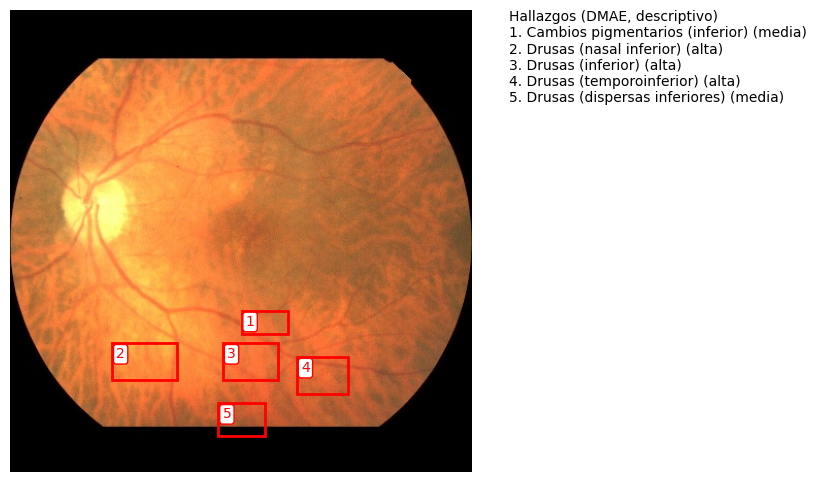

Imagen: /content/retina_paper_style.png


In [ ]:
out_path, final_boxes, warnings = render_paper_style_boxes(
    image_path=image_path,
    report=report,
    out_path="/content/retina_paper_style.png",
    iou_thresh=0.45,
    max_boxes=8,
    drop_incoherent=False,
    dpi=300
)

print("Imagen:", out_path)
if warnings:
    print("\nAdvertencias:")
    for w in warnings:
        print("-", w)

In [ ]:
from IPython.display import display, Markdown
from datetime import datetime

def _fmt_conf(c):
    c = (c or "").strip().lower()
    if c in ("alta", "media", "baja"):
        return c
    return "no_especificada"

def _fmt_xy(x, y, nd=2):
    return f"({x:.{nd}f}, {y:.{nd}f})"

def _fmt_box(b, nd=2):
    return f"({b['x0']:.{nd}f}, {b['y0']:.{nd}f}) → ({b['x1']:.{nd}f}, {b['y1']:.{nd}f})"

def _safe(s):
    return (s or "").replace("\n", " ").strip()

def retina_json_to_markdown_clinical(
    report: dict,
    *,
    study_title: str = "Reporte descriptivo de fondo de ojo",
    version: str = "v1.0",
    analyst: str = "Módulo de interpretación visual automatizada",
    include_methods: bool = True,
    include_disclaimer: bool = True,
    annotated_image_path: str | None = None,  # ej: "/content/retina_paper_style.png"
    image_caption: str = "Imagen anotada con numeración de hallazgos (referencia H#).",
) -> str:
    # --------- Preparación ---------
    image_id = report.get("image_id", "N/A")
    sections = report.get("sections", {}) or {}

    # Hallazgos estructurados
    anns = report.get("annotations", []) or []
    boxes = report.get("boxes", []) or []

    # Normalizar: asignar IDs y construir lista unificada de hallazgos (H1..Hn)
    # Preferimos boxes para referencia clínica (región), pero si no hay boxes, usamos annotations.
    hallazgos = []

    if boxes:
        for b in boxes:
            hallazgos.append({
                "label": _safe(b.get("label", "")),
                "confidence": _fmt_conf(b.get("confidence")),
                "box": b,
                "point": None
            })
    else:
        for a in anns:
            hallazgos.append({
                "label": _safe(a.get("label", "")),
                "confidence": _fmt_conf(a.get("confidence")),
                "box": None,
                "point": a
            })

    # Si existen ambos (boxes + annotations), se incluye además la tabla de annotations como complemento.
    # Se puede hacer matching label->ID, pero mantenemos simple y transparente.

    # --------- Markdown ---------
    md = []
    md.append(f"# {study_title}\n")
    md.append(f"**ID de imagen:** `{image_id}`  ")
    md.append(f"**Generado:** {datetime.now().strftime('%Y-%m-%d %H:%M')}  ")
    md.append(f"**Versión:** {version}  ")
    md.append(f"**Responsable/Agente:** {analyst}\n")

    if include_disclaimer:
        md.append("> **Nota de uso:** Este reporte es **descriptivo** y se basa únicamente en la apariencia visual de la imagen. ")
        md.append("> No constituye diagnóstico, no sustituye la valoración clínica ni estudios complementarios. ")
        md.append("> La interpretación puede verse limitada por la calidad de imagen y el campo de visión.\n")

    # Imagen anotada (opcional)
    if annotated_image_path:
        # En Colab/GitHub, si la imagen está en el mismo directorio del markdown, se renderiza
        md.append("## Evidencia visual\n")
        md.append(f"![{_safe(image_caption)}]({_safe(annotated_image_path)})\n")
        md.append(f"*{_safe(image_caption)}*\n")

    # Resumen ejecutivo
    md.append("## Resumen ejecutivo\n")
    # Extrae lo más relevante (sección 4 + limitaciones)
    s4 = sections.get("4_dmae_descriptivo", [])
    s7 = sections.get("7_limitaciones_notas", [])

    if s4:
        md.append("**Hallazgos descriptivos compatibles con DMAE (según apariencia):**")
        for item in s4[:5]:
            md.append(f"- {item}")
    else:
        md.append("- No se reportaron hallazgos descriptivos compatibles con DMAE en la sección (4).")

    if s7:
        md.append("\n**Limitaciones principales:**")
        for item in s7[:3]:
            md.append(f"- {item}")
    md.append("")

    # Secciones clínicas (estructura fija)
    section_titles = {
        "1_calidad": "1) Calidad de imagen",
        "2_disco_optico": "2) Disco óptico",
        "3_macula_fovea": "3) Mácula y fóvea",
        "4_dmae_descriptivo": "4) Hallazgos compatibles con DMAE (descriptivo)",
        "5_vasos_vasculometria": "5) Vasos y vasculometría cualitativa",
        "6_otras_lesiones": "6) Otras lesiones visibles",
        "7_limitaciones_notas": "7) Limitaciones y notas",
    }

    md.append("## Descripción estructurada\n")
    for key, title in section_titles.items():
        md.append(f"### {title}\n")
        bullets = sections.get(key, [])
        if bullets:
            for it in bullets:
                md.append(f"- {it}")
        else:
            md.append("- No especificado en el reporte.")
        md.append("")

    # Tabla de hallazgos (H#) – preferencia boxes
    md.append("## Trazabilidad de hallazgos señalados\n")
    if hallazgos:
        md.append("### Tabla de hallazgos (H#)\n")
        md.append("| ID | Etiqueta | Confianza | Región (box) | Punto (x,y) |")
        md.append("|---:|---|:---:|---|---|")
        for i, h in enumerate(hallazgos, start=1):
            hid = f"H{i}"
            label = h["label"] or "—"
            conf = h["confidence"]
            if h["box"]:
                b = h["box"]
                region = _fmt_box(b)
            else:
                region = "—"
            if h["point"]:
                p = h["point"]
                point = _fmt_xy(p["x"], p["y"])
            else:
                point = "—"
            md.append(f"| {hid} | {label} | {conf} | {region} | {point} |")
        md.append("")
    else:
        md.append("- No se incluyeron boxes ni annotations.\n")

    # Tabla de annotations (si existen) como complemento
    if anns:
        md.append("### Puntos de referencia (annotations)\n")
        md.append("| # | Etiqueta | Confianza | (x,y) normalizado |")
        md.append("|---:|---|:---:|---|")
        for i, a in enumerate(anns, start=1):
            md.append(f"| {i} | {_safe(a.get('label'))} | {_fmt_conf(a.get('confidence'))} | {_fmt_xy(a.get('x',0), a.get('y',0))} |")
        md.append("")

    # Tabla de boxes (si existen)
    if boxes:
        md.append("### Regiones delimitadas (boxes)\n")
        md.append("| # | Etiqueta | Confianza | (x0,y0) → (x1,y1) |")
        md.append("|---:|---|:---:|---|")
        for i, b in enumerate(boxes, start=1):
            md.append(f"| {i} | {_safe(b.get('label'))} | {_fmt_conf(b.get('confidence'))} | {_fmt_box(b)} |")
        md.append("")

    # Metodología breve (material de referencia)
    if include_methods:
        md.append("## Metodología de generación (resumen)\n")
        md.append("- El reporte se genera mediante un flujo automatizado que procesa una imagen de fondo de ojo y produce una salida estructurada (JSON) conforme a un esquema fijo.")
        md.append("- El contenido se limita a **descripción visual**; la confianza refleja **claridad visual** (no probabilidad diagnóstica).")
        md.append("- Las coordenadas son **normalizadas** en el rango [0,1], referidas al ancho/alto de la imagen.")
        md.append("- Las regiones delimitadas (boxes) se proponen para facilitar trazabilidad y discusión académica; su precisión depende de la calidad de imagen y del modelo.\n")

    return "\n".join(md)


# --- USO ---
# report = {...}  # tu JSON ya cargado como dict
md_text = retina_json_to_markdown_clinical(
    report,
    study_title="Reporte descriptivo de retina",
    version="v1.0",
    analyst="EyeInsights - Módulo VLM (prototipo experimental)",
    include_methods=True,
    include_disclaimer=True,
    annotated_image_path=None  # pon aquí tu ruta si ya generaste imagen anotada
)

display(Markdown(md_text))

# Reporte descriptivo de retina

**ID de imagen:** `8e5b8825-c258-4e03-888e-3eab782e5486`  
**Generado:** 2026-03-26 00:29  
**Versión:** v1.0  
**Responsable/Agente:** EyeInsights - Módulo VLM (prototipo experimental)

> **Nota de uso:** Este reporte es **descriptivo** y se basa únicamente en la apariencia visual de la imagen. 
> No constituye diagnóstico, no sustituye la valoración clínica ni estudios complementarios. 
> La interpretación puede verse limitada por la calidad de imagen y el campo de visión.

## Resumen ejecutivo

**Hallazgos descriptivos compatibles con DMAE (según apariencia):**
- Presencia de múltiples drusas pequeñas, puntiformes, dispersas principalmente en área macular y hacia temporal superior e inferior.
- Drusas tienen tamaño pequeño a mediano relativo, apariencia amarillo-blanquecina.
- Distribución no homogénea, con algunos conglomerados discretos en cuadrantes temporal superior e inferior y nasal inferior.
- No se observan cambios pigmentarios evidentes ni grandes áreas hipopigmentadas sugestivas de atrofia.
- Ausencia clara de signos de neovascularización (no se identifican hemorragias subretinianas, exudados resaltantes o elevaciones evidentes).

**Limitaciones principales:**
- Desenfoque y menor iluminación periférica nasal limita análisis periférico en esa región.
- Pequeñas variaciones en tono pueden deberse a iluminación o imágenes de fondo.
- Hallazgos discretos, interpretación cuidadosa recomendada.

## Descripción estructurada

### 1) Calidad de imagen

- Enfoque adecuado centralmente, leve desenfoque periférico.
- Iluminación homogénea excepto borde nasal con menor intensidad.
- Campo de visión completo de la retina posterior.
- Leve artefacto de oscurecimiento o viñeteado nasal. No impide evaluación central.

### 2) Disco óptico

- Visible claramente en hemiretina nasal.
- Bordes nítidos y bien definidos.
- Coloración amarilla pálida a naranja.
- Excavación central visible, congruente con imagen típica.

### 3) Mácula y fóvea

- Apariencia algo irregular con escasa pigmentación central.
- Zona foveal visible con ligera depresión.
- Áreas perimaculares con alteraciones sutiles en tonalidad.

### 4) Hallazgos compatibles con DMAE (descriptivo)

- Presencia de múltiples drusas pequeñas, puntiformes, dispersas principalmente en área macular y hacia temporal superior e inferior.
- Drusas tienen tamaño pequeño a mediano relativo, apariencia amarillo-blanquecina.
- Distribución no homogénea, con algunos conglomerados discretos en cuadrantes temporal superior e inferior y nasal inferior.
- No se observan cambios pigmentarios evidentes ni grandes áreas hipopigmentadas sugestivas de atrofia.
- Ausencia clara de signos de neovascularización (no se identifican hemorragias subretinianas, exudados resaltantes o elevaciones evidentes).

### 5) Vasos y vasculometría cualitativa

- Calibre arteriolar ligeramente menor que venular, dentro de parámetros visuales normales.
- Tortuosity leve a moderada de algunos vasos venosos temporales.
- Densidad vascular moderada, con distribución regular.
- Cruces arteriovenosos bien visualizados, sin signos aparentes de alteración.

### 6) Otras lesiones visibles

- No se observan hemorragias visibles.
- No se identifican exudados duros ni algodonosos.
- No hay cicatrices aparentes.

### 7) Limitaciones y notas

- Desenfoque y menor iluminación periférica nasal limita análisis periférico en esa región.
- Pequeñas variaciones en tono pueden deberse a iluminación o imágenes de fondo.
- Hallazgos discretos, interpretación cuidadosa recomendada.

## Trazabilidad de hallazgos señalados

### Tabla de hallazgos (H#)

| ID | Etiqueta | Confianza | Región (box) | Punto (x,y) |
|---:|---|:---:|---|---|
| H1 | Drusas (conglomerado temporal superior) | alta | (0.63, 0.32) → (0.75, 0.48) | — |
| H2 | Drusas (dispersas maculares) | alta | (0.47, 0.53) → (0.56, 0.62) | — |
| H3 | Drusas (conglomerado temporal inferior) | alta | (0.37, 0.51) → (0.45, 0.60) | — |

### Puntos de referencia (annotations)

| # | Etiqueta | Confianza | (x,y) normalizado |
|---:|---|:---:|---|
| 1 | Drusas (conglomerado) | alta | (0.68, 0.43) |
| 2 | Drusas (dispersas) | alta | (0.52, 0.57) |
| 3 | Drusas (conglomerado) | alta | (0.41, 0.56) |

### Regiones delimitadas (boxes)

| # | Etiqueta | Confianza | (x0,y0) → (x1,y1) |
|---:|---|:---:|---|
| 1 | Drusas (conglomerado temporal superior) | alta | (0.63, 0.32) → (0.75, 0.48) |
| 2 | Drusas (dispersas maculares) | alta | (0.47, 0.53) → (0.56, 0.62) |
| 3 | Drusas (conglomerado temporal inferior) | alta | (0.37, 0.51) → (0.45, 0.60) |

## Metodología de generación (resumen)

- El reporte se genera mediante un flujo automatizado que procesa una imagen de fondo de ojo y produce una salida estructurada (JSON) conforme a un esquema fijo.
- El contenido se limita a **descripción visual**; la confianza refleja **claridad visual** (no probabilidad diagnóstica).
- Las coordenadas son **normalizadas** en el rango [0,1], referidas al ancho/alto de la imagen.
- Las regiones delimitadas (boxes) se proponen para facilitar trazabilidad y discusión académica; su precisión depende de la calidad de imagen y del modelo.
